# **Previsão da saída de uma porta lógica AND usando TensorFlow**
Neste tutorial, vamos usar o TensorFlow para construir um modelo de rede neural simples que será capaz de prever a saída de uma porta lógica AND.

### **1. Importando bibliotecas necessárias**
Primeiramente, vamos garantir que o TensorFlow esteja instalado e pronto para uso.

In [32]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

### **2. Conjunto de dados da porta lógica AND**
A porta lógica AND tem duas entradas e uma saída. A tabela verdade da porta AND é a seguinte:

| Entrada 1 | Entrada 2 | Saída (AND) |
|-----------|-----------|-------------|
| 0         | 0         | 0           |
| 0         | 1         | 0           |
| 1         | 0         | 0           |
| 1         | 1         | 1           |

In [33]:
# Entradas (X) e saídas (Y) da porta AND
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
Y = np.array([[0], [0], [0], [1]], dtype=np.float32)

### **3. Construindo o modelo de rede neural**
Vamos construir um modelo de rede neural simples com o TensorFlow, contendo uma camada densa (totalmente conectada) com uma única saída.

Esse bloco de código define um modelo sequencial com uma única camada densa que tem 1 neurônio.
O modelo recebe entradas de dimensão 2 (representando as duas entradas da porta lógica AND).

A função de ativação sigmoide transforma a saída do neurônio em um valor entre 0 e 1, adequado para resolver problemas de classificação binária.

Este modelo será capaz de aprender a mapear as combinações de entradas (0, 1) para a saída correta (0 ou 1) da porta lógica AND.

In [34]:
# Definindo o modelo sequencial
model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=1, activation='sigmoid', input_shape=(2,))
])

### **4. Compilando o modelo**
Agora precisamos compilar o modelo, escolhendo uma função de perda e um otimizador.

In [35]:
# Compilando o modelo
# Compilando o modelo com métricas adicionais (MAE e MSE)
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy', 'mae', 'mse'])

### **5. Treinando o modelo**
Vamos treinar o modelo por 500 épocas e verificar o desempenho.

In [36]:
# Treinando o modelo
history = model.fit(X, Y, epochs=500, verbose=0)

### **6. Avaliando o modelo**
Agora que o modelo foi treinado, podemos testá-lo com as entradas da porta AND para ver suas previsões:

In [37]:
# Fazendo previsões com o modelo treinado
predictions = model.predict(X)

# Convertendo as previsões para valores binários (0 ou 1)
predictions = (predictions > 0.5).astype(int)

# Exibindo as previsões
for i in range(len(X)):
    print(f"Entrada: {X[i]} - Saída esperada: {Y[i]} - Previsão: {predictions[i]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Entrada: [0. 0.] - Saída esperada: [0.] - Previsão: [0]
Entrada: [0. 1.] - Saída esperada: [0.] - Previsão: [0]
Entrada: [1. 0.] - Saída esperada: [0.] - Previsão: [0]
Entrada: [1. 1.] - Saída esperada: [1.] - Previsão: [0]


### **7. Interpretação dos resultados**
As previsões esperadas para as entradas são:
- Entrada $ (0, 0) $ => Saída $ 0 $
- Entrada $ (0, 1) $ => Saída $ 0 $
- Entrada $ (1, 0) $ => Saída $ 0 $
- Entrada $ (1, 1) $ => Saída $ 1 $


### **8. Visualizando a perda e a acurácia**
Podemos também visualizar a perda durante o treinamento para entender como o modelo evoluiu.

* Perda baixa: Geralmente, valores próximos de 0 (como 0.01 ou 0.1) indicam que o modelo está se saindo bem, fazendo previsões muito próximas das saídas corretas.
* Perda moderada: Valores entre 0.2 e 0.5 são comuns no início do treinamento ou em modelos razoáveis, mas ainda podem indicar que o modelo precisa melhorar.
* Perda alta: Valores acima de 0.5 sugerem que o modelo está tendo dificuldade em aprender e está cometendo muitos erros. Em classificações binárias, se a perda estiver perto de 1.0 ou mais, significa que o modelo está bastante distante de realizar previsões corretas.

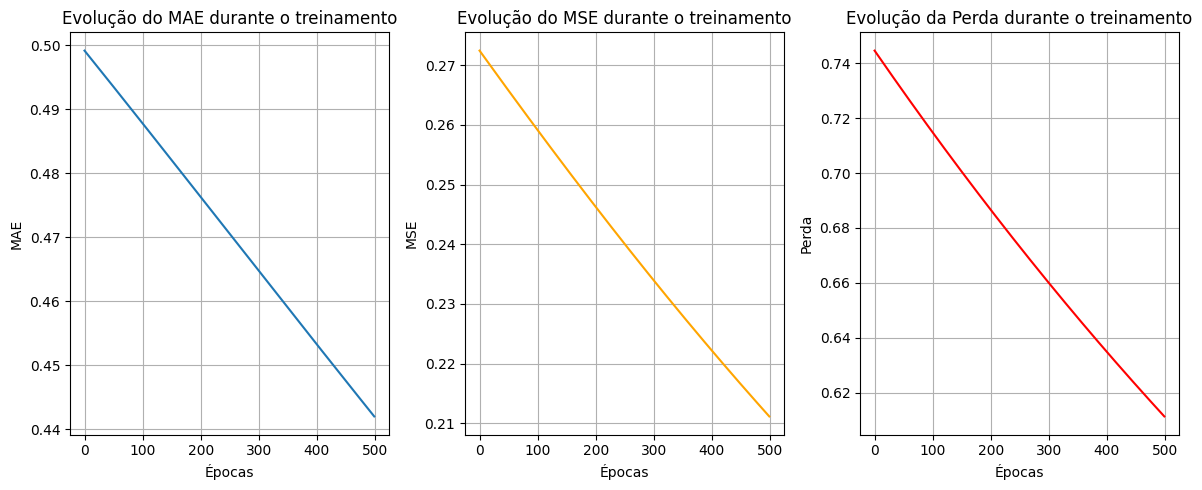

In [38]:
# Visualizando a evolução do MAE, MSE e a perda durante o treinamento
epochs = range(0, len(history.history['loss']))

plt.figure(figsize=(12, 5))

# Gráfico de Erro Médio Absoluto (MAE)
plt.subplot(1, 3, 1)
plt.plot(epochs, history.history['mae'], label='Erro Médio Absoluto (MAE)')
plt.title('Evolução do MAE durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('MAE')
plt.grid(True)

# Gráfico de Erro Quadrático Médio (MSE)
plt.subplot(1, 3, 2)
plt.plot(epochs, history.history['mse'], label='Erro Quadrático Médio (MSE)', color='orange')
plt.title('Evolução do MSE durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.grid(True)

# Gráfico da Perda
plt.subplot(1, 3, 3)
plt.plot(epochs, history.history['loss'], label='Perda', color='red')
plt.title('Evolução da Perda durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.grid(True)

plt.tight_layout()
plt.show()

### **Conclusão**
Neste tutorial, você aprendeu como criar um modelo simples de rede neural com TensorFlow para prever a saída de uma porta lógica AND.